In [1]:
import sys
from pathlib import Path
import importlib

import yaml

import pandas as pd
import numpy as np

sys.path.insert(0, str(Path.cwd().resolve().parents[0] / 'src'))

from ipfnpytools.plot import use_base_style
from ts_profile_fitter.loading import load_shot_list, load_ts_data, load_intervals
import ts_profile_fitter.preprocess as preprocess
importlib.reload(preprocess)
from ts_profile_fitter.preprocess import (
    apply_cold_dense_edge_filters,
    apply_distance_outlier_filters,
    apply_density_outside_separatrix_filter,
    map_to_r_midplane,
    preprocess_ts_data,
)
import ts_profile_fitter.fitting as fitting
importlib.reload(fitting)
from ts_profile_fitter.fitting import (
    compute_channel_knots,
    fit_ipfn_spline_ne_Te_TS,
    fit_modified_tanh_profile,
    fit_mbsplt_ne_Te_TS,
)
from ts_profile_fitter.derived_quantities import compute_profile_quantities
from ts_profile_fitter.figure_naming import make_fig_name

15:47:31 | aug_sfutils | INFO: Using version 0.9.5
15:47:31 | aug_sfutils.mapeq | INFO: AUG-SF home /shares/software/aug-dv/moduledata/miniforge3/2024.09/lib/python3.10/site-packages/aug_sfutils


# Configuration

This section contains the inputs and choices that define one reproducible shot/interval run. The later cells are grouped into preprocessing, fitting, physics, and plotting stages.

In [2]:
repo_root = Path.cwd().resolve().parent
config_path = repo_root / 'configs' / 'pipeline_config_run05_new_outlier.yaml'
config_dir = config_path.parent
with config_path.open('r', encoding='utf-8') as stream:
    pipeline_config = yaml.safe_load(stream) or {}

def resolve_config_path(value, default):
    path = pipeline_config.get(value, default)
    path = Path(path)
    return path if path.is_absolute() else config_dir / path

fit_config = pipeline_config.get('fit_config', {})
preprocess_config = fit_config.get('preprocess', {})
fits_config = fit_config.get('fits', {})
physics_config = fit_config.get('physics', {})

shot_id = 35970
time_requested = 2.7
equilibrium = pipeline_config.get('equilibrium', 'EQH')
data_directory = str(resolve_config_path('data_dir', '../data'))
intervals_path = str(resolve_config_path('database', '../data/intervals.csv'))
output_directory = repo_root / 'plots'
mapping_method = preprocess_config.get('mapping_method', 'ipfnpytools')
r_edge_offset = preprocess_config.get('r_edge_offset', 0.008)
r_zoom = 2.11
r_zoom_max = 2.20
physics_grid_size = physics_config.get('grid_size', 2000)
knot_count_shift = fits_config.get('spline', {}).get('knot_count_shift', 0)

# Notebook plotting controls are intentionally independent of the YAML.
save_figures = False
show_figures = True
close_figures = False

# Parse preprocess configurations from .yaml
rhop_filter = preprocess_config.get('rhop_filter', {})
outlier_config = preprocess_config.get('outlier_config', {})
local_statistical_outlier_config = preprocess_config.get('local_statistical_outlier_config', {})
cold_dense_edge_config = preprocess_config.get('cold_dense_edge_config', {})
density_outside_separatrix_config = preprocess_config.get('density_outside_separatrix_config', {})

# Parse fit configs from .yaml
mtanh_config = fits_config.get('mtanh', {})
spline_config = fits_config.get('spline', {})
#spline_config['knot_strategy'] = 'hybrid'
#knot_count_shift=0
#spline_config['knot_strategy'] = 'hybrid'
#spline_config['knot_count_shift'] = 0

print(f'Loaded configuration: {config_path}')
print(f'Using database: {intervals_path}')
print(f'Notebook plotting: save={save_figures}, show={show_figures}, close={close_figures}')

Loaded configuration: /shares/users/work/joanune/Desktop/TS_profile_fitter/configs/pipeline_config_run05_new_outlier.yaml
Using database: /shares/users/work/joanune/Desktop/TS_profile_fitter/data/34383---38808_database_dt-0.1s.pkl
Notebook plotting: save=False, show=True, close=False


In [3]:
intervals_df = load_intervals(intervals_path)

shot_intervals = intervals_df[intervals_df['shot_id'] == shot_id]
matching_intervals = shot_intervals[
    (shot_intervals['t_begin'] <= time_requested)
    & (time_requested <= shot_intervals['t_end'])
]
if matching_intervals.empty:
    raise ValueError(
        f'No interval found for shot {shot_id} at t={time_requested:.3f} s.'
    )

selected_interval = matching_intervals.iloc[0]
interval = {
    't_begin': float(selected_interval['t_begin']),
    't_end': float(selected_interval['t_end']),
    'label': selected_interval['label'],
}

print(
    f"Shot {shot_id}, t={time_requested:.3f} s -> "
    f"({interval['t_begin']:.3f}, {interval['t_end']:.3f}) s: {interval['label']}"
)

Shot 35970, t=2.700 s -> (2.698, 2.796) s: L-mode


In [4]:
shot_intervals = intervals_df[intervals_df['shot_id'] == shot_id]
shot_intervals[['t_begin', 't_end', 'label']].tail(20)

,t_begin,t_end,label
172,6.155222,6.253778,"ELMy H-mode (small + large ELMs, with QCM)"
173,6.253778,6.352333,"ELMy H-mode (small + large ELMs, with QCM)"
174,6.352333,6.450889,"ELMy H-mode (small + large ELMs, with QCM)"
175,6.450889,6.549444,"ELMy H-mode (small + large ELMs, with QCM)"
176,6.549444,6.648000,"ELMy H-mode (small + large ELMs, with QCM)"
177,6.820000,6.900000,"ELMy H-mode (small + large ELMs, with QCM)"
178,6.900000,6.999286,"developed ELMy H-mode (large ELMs, with QCM)"
179,6.999286,7.098571,"developed ELMy H-mode (large ELMs, with QCM)"
180,7.098571,7.197857,"developed ELMy H-mode (large ELMs, with QCM)"
181,7.197857,7.297143,"developed ELMy H-mode (large ELMs, with QCM)"


In [5]:
import importlib
import ts_profile_fitter.preprocess as preprocess

importlib.reload(preprocess)

<module 'ts_profile_fitter.preprocess' from '/shares/users/work/joanune/Desktop/TS_profile_fitter/src/ts_profile_fitter/preprocess.py'>

In [6]:
ts_dict = load_ts_data(shot_id=shot_id, data_dir=data_directory, equilibrium=equilibrium)
ts_df, preprocess_metadata = preprocess_ts_data(
    ts_dict,
    interval=interval,
    r_edge_offset=r_edge_offset,
    mapping_method=mapping_method,
    outlier_config=outlier_config,
    local_statistical_outlier_config=local_statistical_outlier_config,
    rhop_filter=rhop_filter,
    report_outliers=True,
    return_metadata=True,
)
ts_df, density_outside_separatrix_metadata = apply_density_outside_separatrix_filter(
    ts_df,
    config=density_outside_separatrix_config,
    report=True,
    return_metadata=True,
)
print('Density outside separatrix outliers:', density_outside_separatrix_metadata['filter_counts'])
if not density_outside_separatrix_metadata['removed_rows'].empty:
    print(density_outside_separatrix_metadata['removed_rows'][[
        'system', 'channel_index', 'time', 'r_midplane',
        'Ne', 'Ne_err', 'filter_reason',
    ]].to_string(index=False))

ts_df, cold_dense_edge_metadata = apply_cold_dense_edge_filters(
    ts_df,
    cold_dense_config=cold_dense_edge_config,
    report=True,
    return_metadata=True,
)
print('Cold-dense edge outliers:', cold_dense_edge_metadata['filter_counts'])
if not cold_dense_edge_metadata['removed_rows'].empty:
    print(cold_dense_edge_metadata['removed_rows'][[
        'system', 'channel_index', 'time', 'r_midplane',
        'Te', 'Te_err', 'Ne', 'Ne_err', 'filter_reason',
    ]].to_string(index=False))

"""
# Second pass: target isolated high-Ne points with unrealistically small errors.
distance_outlier_config = {
    'Ne_edge': {
        'enabled': True,
        'n_neighbors': 5,
        'min_points': 3,
        'min_value': 2.0e19,
        'max_relative_error': 0.05,
        'zscore': 5.0,
        'min_scale': 1.0e18,
    },
}
ts_df, distance_outlier_metadata = apply_distance_outlier_filters(
    ts_df,
    distance_outlier_config=distance_outlier_config,
    report=True,
    return_metadata=True,
)

print('Second-pass distance outliers:', distance_outlier_metadata['filter_counts'])
if not distance_outlier_metadata['removed_rows'].empty:
    print(distance_outlier_metadata['removed_rows'][[
        'system', 'channel_index', 'time', 'r_midplane',
        'Ne', 'Ne_err', 'filter_reason',
    ]].to_string(index=False)) """

#ts_df.head()
ts_df = map_to_r_midplane(ts_df)
ts_df.head()

15:47:35 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/augd/VTA/35/35970.1
15:47:35 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/augd/EQH/35/35970.1
15:47:35 | aug_sfutils.sf2equ | INFO: Reading equ scalars
15:47:35 | aug_sfutils.sf2equ | INFO: Reading equ 1d profiles
15:47:36 | aug_sfutils.sf2equ | INFO: Reading equ PFM
15:47:36 | aug_sfutils.sf2equ | INFO: COCO 17


Dimensions before mapping: time: (997, 1) r: (997, 1) z: (1, 16)
Dimensions before mapping: time: (1287, 1) r: (1287, 1) z: (1, 11)
[Measurement Validity Filtering Report]
  - Te_zero_value: 582 points
  - Te_zero_error: 494 points
  - Ne_zero_value: 582 points
  - Ne_negative_value: 359 points
  - Ne_zero_error: 582 points
[Local Statistical Outlier Report: core:Te]
Removed 74 rows; upper-value: 61, relative-error: 22, both: 9.
Skipped for insufficient support; upper-value: 15, relative-error: 15.
[Local Statistical Outlier Report: core:Ne]
Removed 74 rows; upper-value: 65, relative-error: 17, both: 8.
Skipped for insufficient support; upper-value: 15, relative-error: 15.
[Local Statistical Outlier Report: edge:Te]
Removed 988 rows; upper-value: 747, relative-error: 298, both: 57.
Skipped for insufficient support; upper-value: 3, relative-error: 3.
[Local Statistical Outlier Report: edge:Ne]
Removed 396 rows; upper-value: 359, relative-error: 272, both: 235.
Skipped for insufficient s

,system,channel_index,time,r_channel,z_channel,rho_pol,r_midplane,Te,Te_err,Ne,Ne_err,keep,filter_reason
3,core,3,2.699363,1.77825,0.066,0.233652,1.780710,1782.967041,226.365601,3.848157e+19,3.075077e+18,True,
66,core,3,2.749357,1.77825,0.066,0.237955,1.780710,2160.804199,303.972321,3.952986e+19,3.197008e+18,True,
4,core,4,2.699363,1.77825,0.009,0.236521,1.781801,2185.645996,319.892456,3.447240e+19,2.711064e+18,True,
67,core,4,2.749357,1.77825,0.009,0.240996,1.781937,1872.517578,218.476456,4.225876e+19,2.859582e+18,True,
82,core,3,2.757507,1.78095,0.066,0.243755,1.783301,1920.687500,166.467484,4.072378e+19,2.152752e+18,True,


In [7]:
df_te = ts_df[['r_midplane', 'Te', 'Te_err']].dropna().sort_values('r_midplane')
df_ne = ts_df[['r_midplane', 'Ne', 'Ne_err']].dropna().sort_values('r_midplane')

In [8]:
preprocess_metadata.keys()

dict_keys(['removed_rows', 'filter_counts', 'channels_removed', 'channels_before', 'keep_mask', 'measurement_validity_metadata', 'local_statistical_outlier_metadata'])

In [9]:
preprocess_metadata['local_statistical_outlier_metadata']

{'removed_rows':       system  channel_index      time  r_channel  z_channel   rho_pol  \
 3407    core             15  2.724124    1.78635     -0.641  1.042076   
 3439    core             15  2.757507    1.78095     -0.641  1.038761   
 13725   edge              0  2.701863    2.11766      0.404  1.102026   
 13734   edge              9  2.701863    2.11766     -0.156  1.022545   
 13735   edge             10  2.701863    2.11766     -0.224  1.056241   
 13736   edge              0  2.709867    2.12036      0.404  1.104537   
 13737   edge              1  2.709867    2.12036      0.341  1.069548   
 13738   edge              2  2.709867    2.12036      0.279  1.037772   
 13745   edge              9  2.709867    2.12036     -0.156  1.024707   
 13746   edge             10  2.709867    2.12036     -0.224  1.058434   
 13747   edge              0  2.717862    2.12306      0.404  1.109134   
 13757   edge             10  2.717862    2.12306     -0.224  1.064136   
 13758   edge         

In [10]:
fit_params = {}

# Temperature fit: uses the fitter's internal min/max-based initial guess.
te_popt, te_pcov = fit_modified_tanh_profile(
    df_te['r_midplane'].to_numpy(),
    df_te['Te'].to_numpy(),
    df_te['Te_err'].to_numpy(),
    **mtanh_config['Te'],
)
fit_params['Te'] = te_popt
print('Te mtanh params:', te_popt)

# Density fit: independent call, with its own polynomial orders.
ne_popt, ne_pcov = fit_modified_tanh_profile(
    df_ne['r_midplane'].to_numpy(float),
    df_ne['Ne'].to_numpy(float),
    df_ne['Ne_err'].to_numpy(float),
    **mtanh_config['Ne'],
)
fit_params['Ne'] = ne_popt
print('Ne mtanh params:', ne_popt)


RuntimeError: Modified-tanh fit failed; inspect data scale, uncertainties, initial parameters, and polynomial degrees.

In [11]:
x_ne = df_ne['r_midplane'].to_numpy()
y_ne = df_ne['Ne'].to_numpy()
yerr_ne = df_ne['Ne_err'].to_numpy()
print('Ne points:', len(x_ne))
print('Ne x range:', x_ne.min(), x_ne.max())
print('Ne y range:', y_ne.min(), y_ne.max())
print('Ne error range:', yerr_ne.min(), yerr_ne.max())
print('Unique x values:', np.unique(x_ne).size)

Ne points: 195
Ne x range: 1.7807095050811768 2.2072854042053223
Ne y range: 5.922797e+17 4.840914e+19
Ne error range: 5.2106825e+17 7.8534625e+18
Unique x values: 161


In [12]:
x_te = df_te['r_midplane'].to_numpy()
y_te = df_te['Te'].to_numpy()
yerr_te = df_te['Te_err'].to_numpy()
print('Te points:', len(x_te))
print('Te x range:', x_te.min(), x_te.max())
print('Te y range:', y_te.min(), y_te.max())
print('Te error range:', yerr_te.min(), yerr_te.max())
print('Unique x values:', np.unique(x_te).size)

Te points: 195
Te x range: 1.7807095050811768 2.2072854042053223
Te y range: 7.913275 2512.3435
Te error range: 2.6022058 619.3811
Unique x values: 161


In [13]:
df_spline = ts_df[[
    'system',
    'channel_index',
    'r_channel',
    'r_midplane',
    'rho_pol',
    'Ne',
    'Ne_err',
    'Te',
    'Te_err',
]].dropna().sort_values('r_midplane')

ds_spline_knots = df_spline.drop(columns=['r_channel']).rename(columns={
    'r_midplane': 'R_mid',
    'Ne': 'ne',
    'Ne_err': 'ne_err',
})
#spline_config['knot_strategy'] = 'hybrid'
print(f'Using spline configuration: {spline_config}')
ds_spline_input = ds_spline_knots.drop(columns=['system', 'channel_index'])
knots = compute_channel_knots(
    ds_spline_knots,
    preprocess_metadata['channels_before'],
    preprocess_metadata['channels_removed'],
    knot_count_shift=spline_config.get('knot_count_shift', 0),
    strategy=spline_config.get('knot_strategy', 'global_quantile'),
)
print(f'Computed {len(knots)} spline knots: {knots}')

Using spline configuration: {'method': 'ipfn_spline', 'knot_strategy': 'hybrid', 'knot_count_shift': 0, 'dR_fine': 0.002, 'sigma_conv': 0.0, 'dR_channel_max': 0.003, 'ne_scale': 1e+19, 'Te_scale': 1000.0, 'max_step_scale': 3, 'use_errors': True, 's_factor': 1.0, 'mono': 'decreasing', 'maxiter': 500}
Merged core channels 3 and 4 (rho_pol gap=0.00273812, threshold=0.0341051)
Merged core channels 2 and 5 (rho_pol gap=0.00678981, threshold=0.0341051)
Merged core channels 1 and 6 (rho_pol gap=0.0137741, threshold=0.0341051)
Merged core channels 0 and 7 (rho_pol gap=0.0184537, threshold=0.0341051)
Computed 15 spline knots: [1.7851758  1.80587044 1.83900923 1.8780461  1.91844666 1.95847225
 2.00067973 2.03722787 2.07575321 2.11073303 2.13118911 2.13742822
 2.15229285 2.17552751 2.2035352 ]


In [14]:
preprocess_metadata['channels_removed']

{'core': 2, 'edge': 0}

In [15]:
# RELOAD PLOTTING MODULE

import importlib
import ts_profile_fitter.plotting as plotting

importlib.reload(plotting)
use_base_style()

plot_profile_fit = plotting.plot_profile_fit
plot_spline_profile_fit = plotting.plot_spline_profile_fit

# Figure names are initialized before any production plot is created.
n_channels_core = preprocess_metadata['channels_before']['core']
n_channels_edge = preprocess_metadata['channels_before']['edge']
channels_rmvd = preprocess_metadata['channels_removed']['core']
n_knots = len(knots)
figure_names = {
    'ne_mtanh_full': make_fig_name(shot_id, equilibrium, n_knots, interval, 'ne_mtanh_full'),
    'te_mtanh_full': make_fig_name(shot_id, equilibrium, n_knots, interval, 'te_mtanh_full'),
    'ne_spline_full': make_fig_name(shot_id, equilibrium, n_knots, interval, 'ne_spline_full'),
    'te_spline_full': make_fig_name(shot_id, equilibrium, n_knots, interval, 'te_spline_full'),
    'ne_compare_full': make_fig_name(shot_id, equilibrium, n_knots, interval, 'ne_compare_full'),
    'ne_compare_zoom': make_fig_name(shot_id, equilibrium, n_knots, interval, 'ne_compare_zoom'),
    'te_compare_full': make_fig_name(shot_id, equilibrium, n_knots, interval, 'te_compare_full'),
    'te_compare_zoom': make_fig_name(shot_id, equilibrium, n_knots, interval, 'te_compare_zoom'),
    'summary_all': make_fig_name(shot_id, equilibrium, n_knots, interval, 'summary_all'),
}

In [16]:
stat_meta = preprocess_metadata.get("local_statistical_outlier_metadata") or {}
stat_removed = stat_meta.get("removed_rows", ts_df.iloc[0:0].copy())

def get_statistical_outliers(quantity):
    if stat_removed.empty or "filter_reason" not in stat_removed:
        return stat_removed.iloc[0:0].copy()

    reason = stat_removed["filter_reason"].fillna("").astype(str)
    rows = stat_removed.loc[
        reason.str.contains(f"{quantity}_statistical_", regex=False)
    ]
    return rows.dropna(
        subset=["system", "r_midplane", quantity, f"{quantity}_err"]
    )

ne_outliers = get_statistical_outliers("Ne")
core_ne_out = ne_outliers.loc[ne_outliers["system"].eq("core")]
edge_ne_out = ne_outliers.loc[ne_outliers["system"].eq("edge")]
te_outliers = get_statistical_outliers("Te")
core_te_out = te_outliers.loc[te_outliers["system"].eq("core")]
edge_te_out = te_outliers.loc[te_outliers["system"].eq("edge")]

In [17]:
from ts_profile_fitter.plotting import plot_profile_fit

# Use the core/edge labels created by preprocessing.
df_plot_ne = ts_df.dropna(
    subset=['system', 'r_midplane', 'Ne', 'Ne_err', 'time']
)
core_ne = df_plot_ne['system'] == 'core'
edge_ne = df_plot_ne['system'] == 'edge'

fig, ax = plot_profile_fit(
    x_core=df_plot_ne.loc[core_ne, 'r_midplane'].to_numpy(),
    x_edge=df_plot_ne.loc[edge_ne, 'r_midplane'].to_numpy(),
    y_core=df_plot_ne.loc[core_ne, 'Ne'].to_numpy(),
    y_edge=df_plot_ne.loc[edge_ne, 'Ne'].to_numpy(),
    y_err_core=df_plot_ne.loc[core_ne, 'Ne_err'].to_numpy(),
    y_err_edge=df_plot_ne.loc[edge_ne, 'Ne_err'].to_numpy(),
    x_labels='R_mid [m]',
    y_labels='Ne [m$^{-3}$]',
    x_core_out=core_ne_out["r_midplane"].to_numpy(),
    x_edge_out=edge_ne_out["r_midplane"].to_numpy(),
    y_core_out=core_ne_out["Ne"].to_numpy(),
    y_edge_out=edge_ne_out["Ne"].to_numpy(),
    y_err_core_out=core_ne_out["Ne_err"].to_numpy(),
    y_err_edge_out=edge_ne_out["Ne_err"].to_numpy(),
    time_c=df_plot_ne.loc[core_ne, 'time'].to_numpy(),
    time_e=df_plot_ne.loc[edge_ne, 'time'].to_numpy(),
    popt=fit_params['Ne'],
    directory=output_directory,
    close=close_figures,
    save_fig=save_figures,
    show=show_figures,
    nshot=shot_id,
    interval=interval,
    fig_name=figure_names['ne_mtanh_full'],
    y_mins = 0, y_maxs = 0.8e20
)
figure_names['ne_mtanh_full']

KeyError: 'Ne'

In [18]:
# Temperature plot using the original core/edge system labels.
df_plot_te = ts_df.dropna(
    subset=['system', 'r_midplane', 'Te', 'Te_err', 'time']
)
core_te = df_plot_te['system'] == 'core'
edge_te = df_plot_te['system'] == 'edge'

fig, ax = plot_profile_fit(
    x_core=df_plot_te.loc[core_te, 'r_midplane'].to_numpy(),
    x_edge=df_plot_te.loc[edge_te, 'r_midplane'].to_numpy(),
    y_core=df_plot_te.loc[core_te, 'Te'].to_numpy(),
    y_edge=df_plot_te.loc[edge_te, 'Te'].to_numpy(),
    y_err_core=df_plot_te.loc[core_te, 'Te_err'].to_numpy(),
    y_err_edge=df_plot_te.loc[edge_te, 'Te_err'].to_numpy(),
    x_core_out=core_te_out["r_midplane"].to_numpy(),
    x_edge_out=edge_te_out["r_midplane"].to_numpy(),
    y_core_out=core_te_out["Te"].to_numpy(),
    y_edge_out=edge_te_out["Te"].to_numpy(),
    y_err_core_out=core_te_out["Te_err"].to_numpy(),
    y_err_edge_out=edge_te_out["Te_err"].to_numpy(),
    x_labels='R_mid [m]',
    y_labels='Te [eV]',
    time_c=df_plot_te.loc[core_te, 'time'].to_numpy(),
    time_e=df_plot_te.loc[edge_te, 'time'].to_numpy(),
    popt=fit_params['Te'],
    directory=output_directory,
    close=close_figures,
    save_fig=save_figures,
    show=show_figures,
    nshot=shot_id,
    interval=interval,
    fig_name=figure_names['te_mtanh_full'],
    y_maxs=10000

)
fig, ax = plot_profile_fit(
    x_core=df_plot_te.loc[core_te, 'r_midplane'].to_numpy(),
    x_edge=df_plot_te.loc[edge_te, 'r_midplane'].to_numpy(),
    y_core=df_plot_te.loc[core_te, 'Te'].to_numpy(),
    y_edge=df_plot_te.loc[edge_te, 'Te'].to_numpy(),
    y_err_core=df_plot_te.loc[core_te, 'Te_err'].to_numpy(),
    y_err_edge=df_plot_te.loc[edge_te, 'Te_err'].to_numpy(),
    x_core_out=core_te_out["r_midplane"].to_numpy(),
    x_edge_out=edge_te_out["r_midplane"].to_numpy(),
    y_core_out=core_te_out["Te"].to_numpy(),
    y_edge_out=edge_te_out["Te"].to_numpy(),
    y_err_core_out=core_te_out["Te_err"].to_numpy(),
    y_err_edge_out=edge_te_out["Te_err"].to_numpy(),
    x_labels='R_mid [m]',
    y_labels='Te [eV]',
    time_c=df_plot_te.loc[core_te, 'time'].to_numpy(),
    time_e=df_plot_te.loc[edge_te, 'time'].to_numpy(),
    popt=fit_params['Te'],
    directory=output_directory,
    close=close_figures,
    save_fig=save_figures,
    show=show_figures,
    nshot=shot_id,
    interval=interval,
    fig_name=figure_names['te_mtanh_full'],
    y_maxs=1500,
    y_mins=0,
    x_mins = 2.12

)
figure_names['te_mtanh_full']

KeyError: 'Te'

In [19]:
spline_method = spline_config.get('method', 'ondrej_spline')
knot_count_shift = spline_config.get('knot_count_shift', 0)
if spline_method == 'ondrej_spline':
    ds_out, xt, p_ne, pcov_ne, p_Te, pcov_Te = fit_mbsplt_ne_Te_TS(
        ds_spline_input,
        dR_fine=spline_config.get('dR_fine', 5e-4),
        sigma_conv=spline_config.get('sigma_conv', 5e-3),
        R_knots=knots,
        dR_channel_max=spline_config.get('dR_channel_max', 3e-3),
        max_step_scale=spline_config.get('max_step_scale', 3),
        use_errors=spline_config.get('use_errors', True),
        loss=spline_config.get('loss', 'linear'),
        f_scale=spline_config.get('f_scale', 1.0),
        ne_scale=spline_config.get('ne_scale', 1e19),
        Te_scale=spline_config.get('Te_scale', 1e3),
    )
elif spline_method == 'ipfn_spline':
    ds_out, xt, p_ne, pcov_ne, p_Te, pcov_Te = fit_ipfn_spline_ne_Te_TS(
        ds_spline_input,
        dR_fine=spline_config.get('dR_fine', 5e-4),
        R_knots=knots,
        dR_channel_max=spline_config.get('dR_channel_max', 3e-3),
        ne_scale=spline_config.get('ne_scale', 1e19),
        Te_scale=spline_config.get('Te_scale', 1e3),
        s_factor=spline_config.get('s_factor', 1.0),
        s=spline_config.get('s'),
        mono=spline_config.get('mono', 'decreasing'),
        bc_type=spline_config.get('bc_type'),
        maxiter=spline_config.get('maxiter', 200),
        minimize_kw=spline_config.get('minimize_kw'),
    )
else:
    raise ValueError(
        f'Unknown spline method {spline_method!r}; expected '
        "'ondrej_spline' or 'ipfn_spline'."
    )

print(f'Spline fit completed with method: {spline_method}')
print('Knot count shift:', knot_count_shift)
print('Number of knots:', len(knots))
print('Knot locations:', knots)
print('Ne parameters:', p_ne)
print('Te parameters:', p_Te)
print(ds_out.head().to_string(index=False))

Spline fit completed with method: ipfn_spline
Knot count shift: 0
Number of knots: 15
Knot locations: [1.7851758  1.80587044 1.83900923 1.8780461  1.91844666 1.95847225
 2.00067973 2.03722787 2.07575321 2.11073303 2.13118911 2.13742822
 2.15229285 2.17552751 2.2035352 ]
Ne parameters: [3.94543015e+19 3.94546326e+19 3.62312554e+19 3.82466911e+19
 3.08270867e+19 3.22729322e+19 2.95048958e+19 2.51599241e+19
 2.67863142e+19 2.06225257e+19 2.31689331e+19 1.64250614e+19
 1.33741601e+19 2.71800886e+18 3.49904822e+18 1.42741497e+18
 1.42786543e+18]
Te parameters: [1987.60981057 1987.62053684 1554.93338745 1602.9399712  1088.65191082
  602.20148781  673.3360815   479.37381828  389.73710095  266.06117441
  324.91042464  116.67237567   88.12507836   14.56433659   17.31344593
   10.72599911   10.72866763]
 R_mid_spl       ne_spl       dne_spl  lam_ne_spl      Te_spl       dTe_spl   lam_Te_spl
   1.78071 3.945430e+19  3.947188e+16 -999.554657 1987.609811      1.278919 -1554.133277
   1.78271 3.9429

# Figure Naming

Every saved figure uses the shot, equilibrium, knot count, exact interval bounds, and a controlled plot descriptor.

In [20]:
figure_names = {
    'ne_mtanh_full': make_fig_name(shot_id, equilibrium, n_knots, interval, 'ne_mtanh_full'),
    'te_mtanh_full': make_fig_name(shot_id, equilibrium, n_knots, interval, 'te_mtanh_full'),
    'ne_spline_full': make_fig_name(shot_id, equilibrium, n_knots, interval, 'ne_spline_full'),
    'te_spline_full': make_fig_name(shot_id, equilibrium, n_knots, interval, 'te_spline_full'),
    'ne_compare_full': make_fig_name(shot_id, equilibrium, n_knots, interval, 'ne_compare_full'),
    'ne_compare_zoom': make_fig_name(shot_id, equilibrium, n_knots, interval, 'ne_compare_zoom'),
    'te_compare_full': make_fig_name(shot_id, equilibrium, n_knots, interval, 'te_compare_full'),
    'te_compare_zoom': make_fig_name(shot_id, equilibrium, n_knots, interval, 'te_compare_zoom'),
    'summary_all': make_fig_name(shot_id, equilibrium, n_knots, interval, 'summary_all'),
}
figure_names

{'ne_mtanh_full': 'shot35970_EQH_k15_t2p698-2p796_ne_mtanh_full',
 'te_mtanh_full': 'shot35970_EQH_k15_t2p698-2p796_te_mtanh_full',
 'ne_spline_full': 'shot35970_EQH_k15_t2p698-2p796_ne_spline_full',
 'te_spline_full': 'shot35970_EQH_k15_t2p698-2p796_te_spline_full',
 'ne_compare_full': 'shot35970_EQH_k15_t2p698-2p796_ne_compare_full',
 'ne_compare_zoom': 'shot35970_EQH_k15_t2p698-2p796_ne_compare_zoom',
 'te_compare_full': 'shot35970_EQH_k15_t2p698-2p796_te_compare_full',
 'te_compare_zoom': 'shot35970_EQH_k15_t2p698-2p796_te_compare_zoom',
 'summary_all': 'shot35970_EQH_k15_t2p698-2p796_summary_all'}

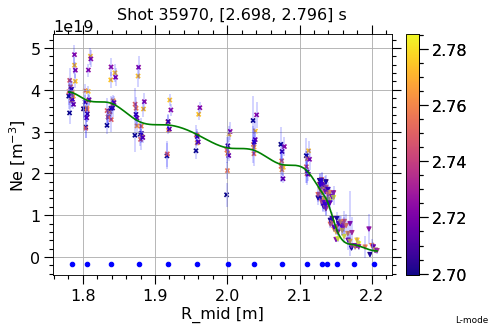

(<Figure size 535.433x330.916 with 3 Axes>,
 <Axes: xlabel='R_mid [m]', ylabel='Ne [m$^{-3}$]'>)

In [21]:
from ts_profile_fitter.plotting import plot_spline_profile_fit

df_plot = ts_df.dropna(
    subset=['system', 'r_midplane', 'Ne', 'Ne_err', 'Te', 'Te_err', 'time']
)

core = df_plot['system'] == 'core'
edge = df_plot['system'] == 'edge'

# Density spline plot
plot_spline_profile_fit(
    x_core=df_plot.loc[core, 'r_midplane'].to_numpy(),
    x_edge=df_plot.loc[edge, 'r_midplane'].to_numpy(),
    y_core=df_plot.loc[core, 'Ne'].to_numpy(),
    y_edge=df_plot.loc[edge, 'Ne'].to_numpy(),
    y_err_core=df_plot.loc[core, 'Ne_err'].to_numpy(),
    y_err_edge=df_plot.loc[edge, 'Ne_err'].to_numpy(),
    ds_out=ds_out,
    quantity='Ne',
    knot_pos=knots,
    x_labels='R_mid [m]',
    y_labels='Ne [m$^{-3}$]',
    time_c=df_plot.loc[core, 'time'].to_numpy(),
    time_e=df_plot.loc[edge, 'time'].to_numpy(),
    directory=output_directory,
    nshot=shot_id,
    interval=interval,
    fig_name=figure_names['ne_spline_full'],
    show=show_figures,
    close=close_figures,
    save_fig=save_figures,
)


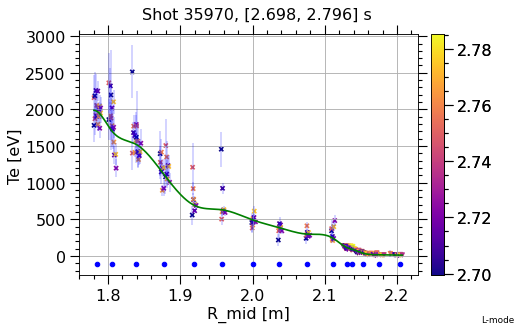

(<Figure size 535.433x330.916 with 3 Axes>,
 <Axes: xlabel='R_mid [m]', ylabel='Te [eV]'>)

In [22]:
core = df_plot['system'] == 'core'
edge = df_plot['system'] == 'edge'

# Temperature spline plot
plot_spline_profile_fit(
    x_core=df_plot.loc[core, 'r_midplane'].to_numpy(),
    x_edge=df_plot.loc[edge, 'r_midplane'].to_numpy(),
    y_core=df_plot.loc[core, 'Te'].to_numpy(),
    y_edge=df_plot.loc[edge, 'Te'].to_numpy(),
    y_err_core=df_plot.loc[core, 'Te_err'].to_numpy(),
    y_err_edge=df_plot.loc[edge, 'Te_err'].to_numpy(),
    ds_out=ds_out,
    quantity='Te',
    knot_pos=knots,
    x_labels='R_mid [m]',
    y_labels='Te [eV]',
    time_c=df_plot.loc[core, 'time'].to_numpy(),
    time_e=df_plot.loc[edge, 'time'].to_numpy(),
    directory=output_directory,
    nshot=shot_id,
    interval=interval,
    fig_name=figure_names['te_spline_full'],
    show=show_figures,
    close=close_figures,
    save_fig=save_figures,
)


In [57]:
ds_out.head().to_string(index=False)

' R_mid_spl       ne_spl       dne_spl  lam_ne_spl      Te_spl       dTe_spl  lam_Te_spl\n  1.790188 9.399761e+19 -3.643728e+20    0.257971 3644.432679 -23012.607214    0.158367\n  1.792188 9.331509e+19 -3.187103e+20    0.292790 3593.312808 -27965.078827    0.128493\n  1.794188 9.272050e+19 -2.764528e+20    0.335394 3533.141105 -32064.438784    0.110189\n  1.796188 9.220701e+19 -2.376004e+20    0.388076 3465.623794 -35310.687085    0.098147\n  1.798188 9.176783e+19 -2.021531e+20    0.453952 3392.467098 -37703.823729    0.089977'

In [58]:
# Load interval-averaged power-balance and geometry inputs.
sys.path.insert(0, '/shares/users/work/joanune/Desktop/pysepest')

import ts_profile_fitter.loading as loading
importlib.reload(loading)
load_physics_inputs = loading.load_physics_inputs

import ts_profile_fitter.fitting as fitting
importlib.reload(fitting)
modified_tanh = fitting.modified_tanh

import ts_profile_fitter.derived_quantities as derived_quantities
importlib.reload(derived_quantities)
compute_equilibrium_separatrix = derived_quantities.compute_equilibrium_separatrix
compute_physics_separatrix = derived_quantities.compute_physics_separatrix
get_connection_length = derived_quantities.get_connection_length

from pysepest.optimizers import first_0_crossing

physics_inputs = load_physics_inputs(
    shot_id,
    interval,
    equilibrium='EQH',
)

power_balance = physics_inputs['power_balance']
geometry = physics_inputs['geometry']
print('Power-balance inputs:', power_balance)
print('Geometry inputs:', geometry)


23:11:57 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/augd/EQH/38/38067.1


23:11:57 | aug_sfutils.sf2equ | INFO: Reading equ scalars
23:11:57 | aug_sfutils.sf2equ | INFO: Reading equ 1d profiles
23:11:58 | aug_sfutils.sf2equ | INFO: Reading equ PFM
23:11:58 | aug_sfutils.sf2equ | INFO: COCO 17
23:11:59 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/augd/TTH/38/38067.1
23:11:59 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/davidp/BPT/38/38067.1
23:11:59 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/augd/TOT/38/38067.1
23:11:59 | aug_sfutils.sfread | ERROR: Shotfile not found for AUGD:ELM(0) #38067
23:11:59 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/augd/GQH/38/38067.1
23:11:59 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/augd/FPC/38/38067.1
23:11:59 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/augd/MBI/38/38067.1
23:11:59 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug

Magnetic Fields:
B_pol_analytic: 0.1967411273645233, B_pol_out: 0.273356657148783, B_tor_out: -1.9174162149429321, B_tor_mbi: -2.495321900844574
Power-balance inputs: {'P_abs': 2959886.25990099, 'P_rsep': 1675207.6666666667, 'dWdt': 0.0, 'dWdt_err': 0.0}
Geometry inputs: {'R_out': 2.147678852081299, 'B_pol': 0.273356657148783, 'B_tor': -1.9174162149429321, 'Z_eff': 1.5}


In [59]:
ts_dict['equ'].time

SFOBJ([0.0666, 0.0726, 0.0736, ..., 9.5336, 9.5366, 9.7536], dtype='>f4')

In [60]:
# Add connection length and compute all three separatrix locations.
sys.path.insert(0, '/shares/users/work/joanune/Desktop/aug_separatrix')
from get_connection_length import get_LcSOL

L_par = get_connection_length(
    shot_id,
    interval,
    provider=get_LcSOL,
    dR=1e-3,
)
geometry['L_par'] = L_par
print('Connection length [m]:', L_par)

# Equilibrium-defined separatrix: rho_pol = 1 at the outer midplane.
eqh_result = compute_equilibrium_separatrix(
    ts_dict['equ'],
    interval,
    rho_sep=1.0,
)
print('EQH Rsep [m]:', eqh_result['Rsep_eqh'])

R_min = max(df_te['r_midplane'].min(), df_ne['r_midplane'].min())
R_max = min(df_te['r_midplane'].max(), df_ne['r_midplane'].max())
R_test = np.linspace(R_min, R_max, physics_grid_size)

mtanh_result = compute_physics_separatrix(
    R=R_test,
    Te=modified_tanh(R_test, *te_popt),
    Ne=modified_tanh(R_test, *ne_popt),
    power_balance=power_balance,
    geometry=geometry,
    fit_method='mtanh',
    optimizer=first_0_crossing,
)

spline_result = compute_physics_separatrix(
    R=ds_out['R_mid_spl'].to_numpy(),
    Te=ds_out['Te_spl'].to_numpy(),
    Ne=ds_out['ne_spl'].to_numpy(),
    dTe_dR=ds_out['dTe_spl'].to_numpy(),
    dNe_dR=ds_out['dne_spl'].to_numpy(),
    power_balance=power_balance,
    geometry=geometry,
    fit_method='spline',
    optimizer=first_0_crossing,
)

print('mtanh Rsep [m]:', mtanh_result['Rsep'])
print('spline Rsep [m]:', spline_result['Rsep'])
print('mtanh Te_sep [eV]:', mtanh_result.get('Te_sep'))
print('spline Te_sep [eV]:', spline_result.get('Te_sep'))
print('mtanh mismatch:', mtanh_result.get('model_mismatch'))
print('spline mismatch:', spline_result.get('model_mismatch'))


23:11:59 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/augd/EQH/38/38067.1
23:11:59 | aug_sfutils.manage_ed | WARNING: File /shares/experiments/aug-shotfiles/augd/MAY/edcntl_dir/38/ed_cntl not found
23:11:59 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/augd/MAY/38/38067
23:12:00 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/augd/EQH/38/38067.1
23:12:00 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/augd/GQH/38/38067.1
23:12:00 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/augd/FPC/38/38067.1
/u/joanune/ipfnpytools/ipfnpytools/trhopz_to_r.py:124: RuntimeWarning: invalid value encountered in sqrt
  values=np.array(np.swapaxes(np.sqrt((eq.pfm - eq.psi0)/(eq.psix-eq.psi0)), 0, 2), dtype=data_type),


Connection length [m]: 36.8252936376417
EQH Rsep [m]: 2.147826671600342
mtanh Rsep [m]: 2.139440647548519
spline Rsep [m]: 2.1399242905573113
mtanh Te_sep [eV]: 142.87939949645553
spline Te_sep [eV]: 100.26121497510076
mtanh mismatch: -10785073.747813582
spline mismatch: -389551.9354608059


In [61]:
np.save('my_file.npy', ds_out) 


In [62]:
spline_result.keys()

dict_keys(['P_e_SOL', 'R', 'B_pol', 'B_tor', 'L_par', 'Zeff', 'q_distribution', 'Te', 'lam_Te', 'Ne', 'lam_Ne', 'lam_q', 'A_SOL', 'q_par_P_SOL', 'kappa_0', 'q_par_SH', 'x_sep', 'model_mismatch', 'Rsep', 'Te_sep', 'Ne_sep', 'lambda_Ne_sep', 'lambda_p_sep', 'P_SOL', 'fit_method', 'R_grid', 'mismatch_grid', 'Te_grid', 'lam_Te_grid', 'lam_q_grid', 'q_par_P_SOL_grid', 'q_par_SH_grid', 'optimizer_result'])

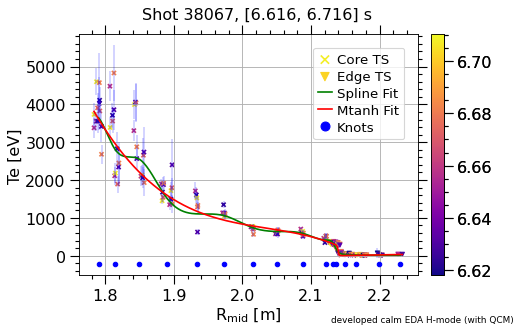

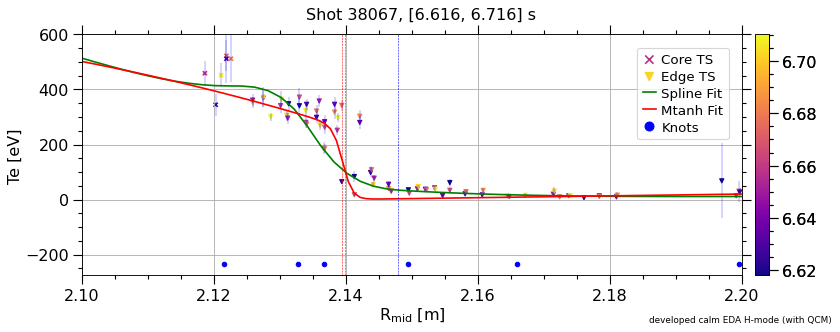

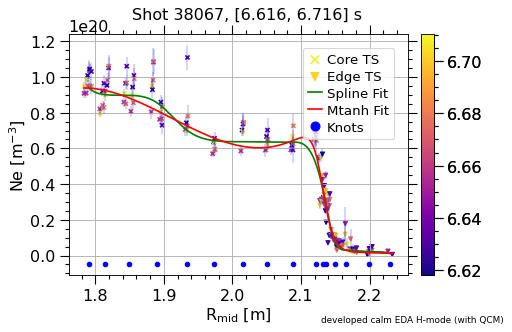

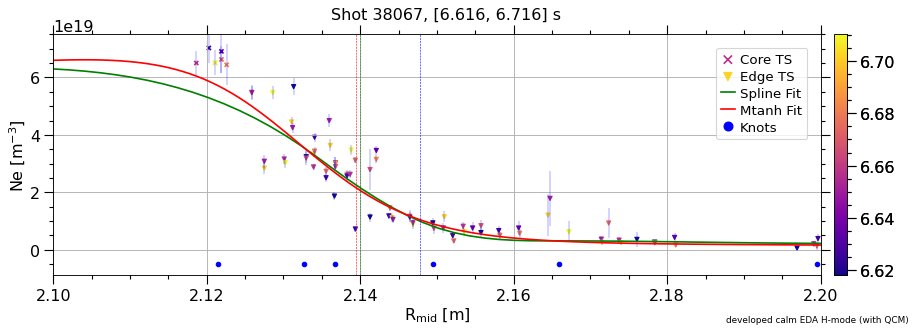

(<Figure size 963.78x330.916 with 3 Axes>,
 <Axes: xlabel='$R_{\\mathrm{mid}}$ [m]', ylabel='Ne [m$^{-3}$]'>)

In [69]:
importlib.reload(plotting)

plot_profile_comparison_full = plotting.plot_profile_comparison_full
plot_profile_comparison_zoomed = plotting.plot_profile_comparison_zoomed

comparison_common = {
    'ds_out': ds_out,
    'knot_pos': knots,
    'nshot': shot_id,
    'interval': interval,
    'directory': output_directory,
    'show': show_figures,
    'close': close_figures,
    'save_fig': save_figures,
}

# Full-range temperature comparison
plot_profile_comparison_full(
    x_core=df_plot_te.loc[core_te, 'r_midplane'].to_numpy(),
    x_edge=df_plot_te.loc[edge_te, 'r_midplane'].to_numpy(),
    y_core=df_plot_te.loc[core_te, 'Te'].to_numpy(),
    y_edge=df_plot_te.loc[edge_te, 'Te'].to_numpy(),
    y_err_core=df_plot_te.loc[core_te, 'Te_err'].to_numpy(),
    y_err_edge=df_plot_te.loc[edge_te, 'Te_err'].to_numpy(),
    quantity='Te',
    mtanh_popt=te_popt,
    time_c=df_plot_te.loc[core_te, 'time'].to_numpy(),
    time_e=df_plot_te.loc[edge_te, 'time'].to_numpy(),
    fig_name=figure_names['te_compare_full'],
    **comparison_common,
)

# Zoomed temperature comparison
plot_profile_comparison_zoomed(
    2.10,
    2.20,
    x_core=df_plot_te.loc[core_te, 'r_midplane'].to_numpy(),
    x_edge=df_plot_te.loc[edge_te, 'r_midplane'].to_numpy(),
    y_core=df_plot_te.loc[core_te, 'Te'].to_numpy(),
    y_edge=df_plot_te.loc[edge_te, 'Te'].to_numpy(),
    y_err_core=df_plot_te.loc[core_te, 'Te_err'].to_numpy(),
    y_err_edge=df_plot_te.loc[edge_te, 'Te_err'].to_numpy(),
    quantity='Te',
    mtanh_popt=te_popt,
    time_c=df_plot_te.loc[core_te, 'time'].to_numpy(),
    time_e=df_plot_te.loc[edge_te, 'time'].to_numpy(),
    Rsep_eqh=eqh_result['Rsep_eqh'],
    Rsep_spline=spline_result['Rsep'],
    Rsep_mtanh=mtanh_result['Rsep'],
    fig_name=figure_names['te_compare_zoom'],
    y_maxs = 600,
    h_factor=1.6,
    **comparison_common,
)

# Full-range density comparison
plot_profile_comparison_full(
    x_core=df_plot_ne.loc[core_ne, 'r_midplane'].to_numpy(),
    x_edge=df_plot_ne.loc[edge_ne, 'r_midplane'].to_numpy(),
    y_core=df_plot_ne.loc[core_ne, 'Ne'].to_numpy(),
    y_edge=df_plot_ne.loc[edge_ne, 'Ne'].to_numpy(),
    y_err_core=df_plot_ne.loc[core_ne, 'Ne_err'].to_numpy(),
    y_err_edge=df_plot_ne.loc[edge_ne, 'Ne_err'].to_numpy(),
    quantity='Ne',
    mtanh_popt=ne_popt,
    time_c=df_plot_ne.loc[core_ne, 'time'].to_numpy(),
    time_e=df_plot_ne.loc[edge_ne, 'time'].to_numpy(),
    fig_name=figure_names['ne_compare_full'],
    **comparison_common,
)

# Zoomed density comparison
plot_profile_comparison_zoomed(
    2.10,
    2.20,
    x_core=df_plot_ne.loc[core_ne, 'r_midplane'].to_numpy(),
    x_edge=df_plot_ne.loc[edge_ne, 'r_midplane'].to_numpy(),
    y_core=df_plot_ne.loc[core_ne, 'Ne'].to_numpy(),
    y_edge=df_plot_ne.loc[edge_ne, 'Ne'].to_numpy(),
    y_err_core=df_plot_ne.loc[core_ne, 'Ne_err'].to_numpy(),
    y_err_edge=df_plot_ne.loc[edge_ne, 'Ne_err'].to_numpy(),
    quantity='Ne',
    mtanh_popt=ne_popt,
    time_c=df_plot_ne.loc[core_ne, 'time'].to_numpy(),
    time_e=df_plot_ne.loc[edge_ne, 'time'].to_numpy(),
    Rsep_eqh=eqh_result['Rsep_eqh'],
    Rsep_spline=spline_result['Rsep'],
    Rsep_mtanh=mtanh_result['Rsep'],
    fig_name=figure_names['ne_compare_zoom'],
    y_maxs = 7.5e19,
    h_factor=1.8,
    **comparison_common,
)


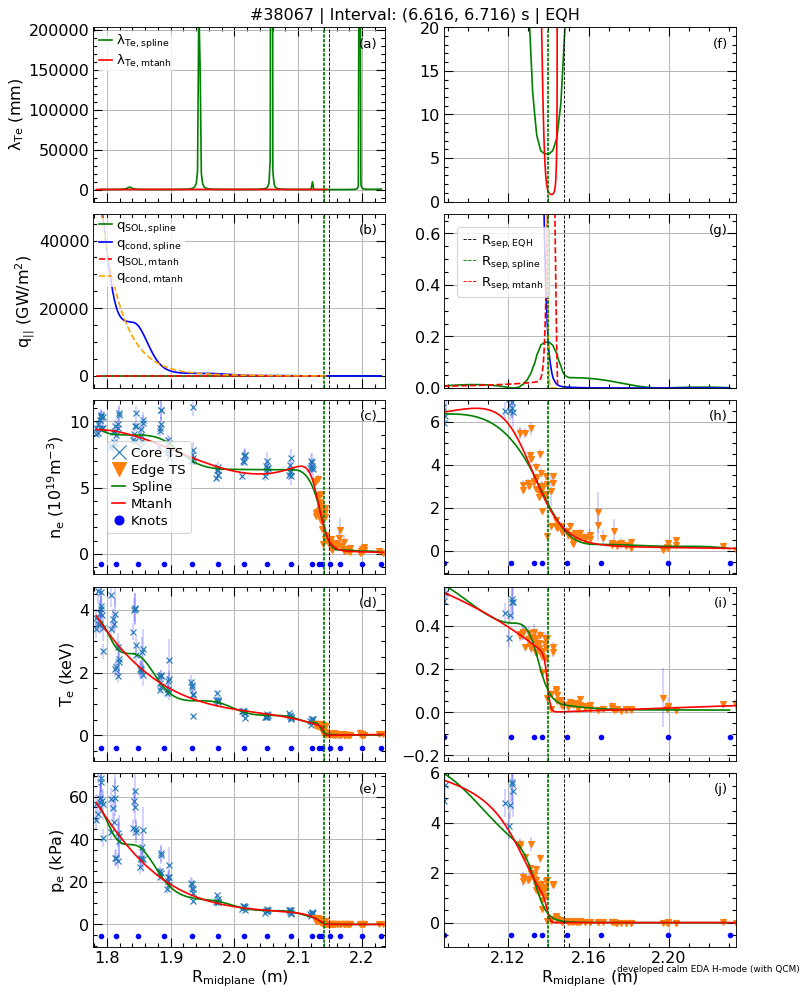

In [64]:
# Complete lambda, heat-flux, density, temperature, and pressure summary.
importlib.reload(plotting)
plot_profile_summary = plotting.plot_profile_summary

fig, ax = plot_profile_summary(
    x_core=df_plot_ne.loc[core_ne, 'r_midplane'].to_numpy(),
    x_edge=df_plot_ne.loc[edge_ne, 'r_midplane'].to_numpy(),
    ne_core=df_plot_ne.loc[core_ne, 'Ne'].to_numpy(),
    ne_edge=df_plot_ne.loc[edge_ne, 'Ne'].to_numpy(),
    te_core=df_plot_te.loc[core_te, 'Te'].to_numpy(),
    te_edge=df_plot_te.loc[edge_te, 'Te'].to_numpy(),
    ne_err_core=df_plot_ne.loc[core_ne, 'Ne_err'].to_numpy(),
    ne_err_edge=df_plot_ne.loc[edge_ne, 'Ne_err'].to_numpy(),
    te_err_core=df_plot_te.loc[core_te, 'Te_err'].to_numpy(),
    te_err_edge=df_plot_te.loc[edge_te, 'Te_err'].to_numpy(),
    ds_out=ds_out,
    R_spline=spline_result['R_grid'],
    R_mtanh=mtanh_result['R_grid'],
    te_popt=te_popt,
    ne_popt=ne_popt,
    lambda_spline=spline_result['lam_Te_grid'],
    lambda_mtanh=mtanh_result['lam_Te_grid'],
    q_sol_spline=spline_result['q_par_P_SOL_grid'],
    q_cond_spline=spline_result['q_par_SH_grid'],
    q_sol_mtanh=mtanh_result['q_par_P_SOL_grid'],
    q_cond_mtanh=mtanh_result['q_par_SH_grid'],
    q_intersection_values=[
        spline_result['q_par_P_SOL'] ,
        mtanh_result['q_par_P_SOL'] ,
    ],
    Rsep_eqh=eqh_result['Rsep_eqh'],
    Rsep_spline=spline_result['Rsep'],
    Rsep_mtanh=mtanh_result['Rsep'],
    knot_pos=knots,
    nshot=shot_id,
    interval=interval,
    equilibrium=equilibrium,
    r_zoom=r_zoom,
    directory=output_directory,
    fig_name=figure_names['summary_all'],
    save_fig=save_figures,
    show=False,
    close=True,
)
ax[0][1].set_ylim(0,20)  # Example limits, adjust as needed
fig

In [65]:
# Shot-level power and stored-energy diagnostic plot.
import ts_profile_fitter.loading as loading
import ts_profile_fitter.plotting as plotting

importlib.reload(loading)
importlib.reload(plotting)
shot_list_path = resolve_config_path('shot_list', '../configs/shot_list.csv')
shot_list_df = loading.load_shot_list(str(shot_list_path))
shot_rows = shot_list_df[shot_list_df['shot_id'].astype(int) == int(shot_id)]
shot_description = (
    shot_rows.iloc[0].get('description') if not shot_rows.empty else None
)
power_data = loading.load_power_signals(shot_id, interval=interval)

23:12:02 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/augd/TOT/38/38067.1
23:12:03 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/augd/TTH/38/38067.1
23:12:03 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/augd/GQH/38/38067.1
23:12:03 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/davidp/BPT/38/38067.1


23:12:03 | aug_sfutils.sfread | ERROR: Shotfile not found for AUGD:ELM(0) #38067


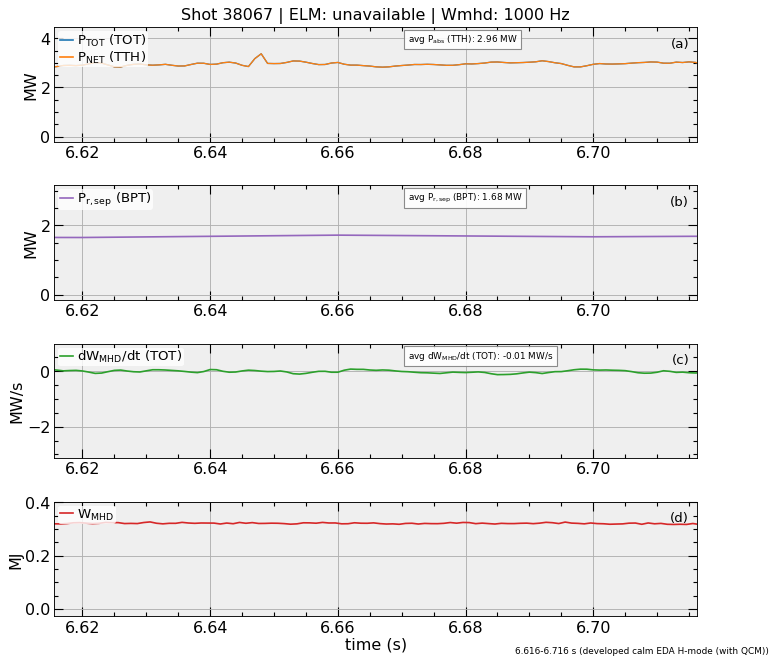

In [66]:
power_fig, power_axes = plotting.plot_power_signals(
    power_data,
    shot_id=shot_id,
    shot_description=shot_description,
    directory=output_directory,
    fig_name=figure_names['summary_all'] + '_power',
    interval=interval,
    save_fig=False,
    h_factor = 1.5,
    close=close_figures,
    show=show_figures,
)

In [67]:
ts_df['r_midplane']

82     1.783437
35     1.783437
36     1.786574
83     1.786983
3      1.788619
         ...   
112    2.199649
141    2.203604
104    2.203604
120    2.226923
103    2.233196
Name: r_midplane, Length: 162, dtype: float64

23:12:03 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/augd/VTA/38/38067.1
23:12:03 | aug_sfutils.sfread | INFO: Fetching SF /shares/experiments/aug-shotfiles/augd/EQH/38/38067.1
23:12:03 | aug_sfutils.sf2equ | INFO: Reading equ scalars
23:12:03 | aug_sfutils.sf2equ | INFO: Reading equ 1d profiles
23:12:04 | aug_sfutils.sf2equ | INFO: Reading equ PFM
23:12:04 | aug_sfutils.sf2equ | INFO: COCO 17


Dimensions before mapping: time: (691, 1) r: (691, 1) z: (1, 16)
Dimensions before mapping: time: (1181, 1) r: (1181, 1) z: (1, 11)


/u/joanune/ipfnpytools/ipfnpytools/trz_to_rhop.py:61: RuntimeWarning: invalid value encountered in sqrt
  values=np.array(np.sqrt((eq.pfm - eq.psi0)/(eq.psix-eq.psi0)), dtype=np.float32),
/u/joanune/ipfnpytools/ipfnpytools/trhopz_to_r.py:124: RuntimeWarning: invalid value encountered in sqrt
  values=np.array(np.swapaxes(np.sqrt((eq.pfm - eq.psi0)/(eq.psix-eq.psi0)), 0, 2), dtype=data_type),


Figure saved to /shares/users/work/joanune/Desktop/TESE_Joao_Pedro_Nunes/chapters/Formulation_and_Methods/Data_Processing/figures/AUG_38067_t6.0_s_EQH_TS_mapping.pdf


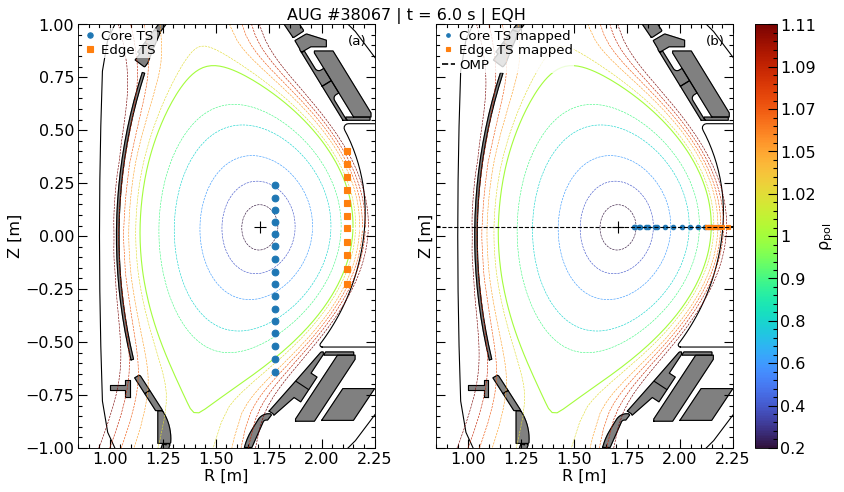

In [68]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from ipfnpytools.plot import plots as ipfn_plots
from ipfnpytools.save_figure import save_figure
from ts_profile_fitter.loading import load_ts_data

time_s = 6.0
equilibrium_name = 'EQH'

ts_data = load_ts_data(
    shot_id=shot_id,
    data_dir=data_directory,
    equilibrium=equilibrium_name,
)
equ = ts_data['equ']

mapped_ts_data = preprocess.convert_vta_to_r_midplane(
    ts_data,
    r_edge_offset=r_edge_offset,
    mapping_method=mapping_method,
    apply_filters=False,
)

rhop = np.array([0.2, 0.4, 0.6, 0.8, 0.9, 1.0, 1.02, 1.05, 1.07, 1.09, 1.11])
theta = np.linspace(0, 2 * np.pi, 256, endpoint=False)

r_flux, z_flux = equ.rhoTheta2rz(
    rhop, theta, t_in=time_s, coord_in='rho_pol'
)
r_axis, z_axis = equ.rhoTheta2rz(
    [0.0], [0.0], t_in=time_s, coord_in='rho_pol'
)

equ_times = np.asarray(equ.time, dtype=float).ravel()
z_mag_values = np.asarray(equ.Zmag, dtype=float).ravel()
equilibrium_order = np.argsort(equ_times)
z_mag = float(np.interp(
    time_s,
    equ_times[equilibrium_order],
    z_mag_values[equilibrium_order],
))

ts_positions = {}
for system_name in ('core', 'edge'):
    system_data = mapped_ts_data.loc[
        mapped_ts_data['system'].eq(system_name)
    ].copy()

    available_times = system_data['time'].dropna()
    nearest_index = (available_times - time_s).abs().idxmin()
    nearest_time = system_data.loc[nearest_index, 'time']

    ts_positions[system_name] = system_data.loc[
        system_data['time'].eq(nearest_time)
    ].sort_values('channel_index')

rho_cmap = plt.get_cmap('turbo')
rho_norm = Normalize(vmin=0, vmax=len(rhop) - 1)

plot_x, plot_y, plot_boxes = [], [], []
plot_labels, plot_types = [], []
plot_linestyles, plot_linewidths = [], []
plot_markers, plot_markersizes, plot_kw = [], [], []


def add_dataset(
    box, x, y, label=None, color='black', linestyle='-',
    linewidth=1.0, marker=None, markersize=None,
):
    plot_x.append(np.asarray(x))
    plot_y.append(np.asarray(y))
    plot_boxes.append(box)
    plot_labels.append(label)
    plot_types.append('trace')
    plot_linestyles.append(linestyle)
    plot_linewidths.append(linewidth)
    plot_markers.append(marker)
    plot_markersizes.append(markersize)
    plot_kw.append({'color': color})


for box in (0, 1):
    for index, rho in enumerate(rhop):
        add_dataset(
            box,
            r_flux[0, :, index],
            z_flux[0, :, index],
            color=rho_cmap(rho_norm(index)),
            linestyle='-' if np.isclose(rho, 1.0) else '--',
            linewidth=1.0 if np.isclose(rho, 1.0) else 0.55,
        )

    axis_x = [float(np.asarray(r_axis).reshape(-1)[0])]
    axis_y = [float(np.asarray(z_axis).reshape(-1)[0])]
    add_dataset(
        box, axis_x, axis_y,
        color='black', linestyle='', linewidth=0,
        marker='+', markersize=11,
    )

    if box == 0:
        for system_name, color, marker in [
            ('core', 'tab:blue', 'o'),
            ('edge', 'tab:orange', 's'),
        ]:
            system_data = ts_positions[system_name]
            add_dataset(
                box,
                system_data['r_channel'].to_numpy(),
                system_data['z_channel'].to_numpy(),
                label=f'{system_name.title()} TS',
                color=color,
                linestyle='None',
                linewidth=0,
                marker=marker,
                markersize=6,
            )
    else:
        for system_name, color, marker in [
            ('core', 'tab:blue', 'o'),
            ('edge', 'tab:orange', 's'),
        ]:
            system_data = ts_positions[system_name]
            add_dataset(
                box,
                system_data['r_midplane'].to_numpy(),
                np.full(len(system_data), z_mag),
                label=f'{system_name.title()} TS mapped',
                color=color,
                linestyle='None',
                linewidth=0,
                marker=marker,
                markersize=4,
            )

        add_dataset(
            box,
            [0.85, 2.25],
            [z_mag, z_mag],
            label='OMP',
            color='black',
            linestyle='--',
            linewidth=1.0,
        )

fig_flux, axes_flux = ipfn_plots(
    x=plot_x,
    y=plot_y,
    boxes=plot_boxes,
    n_boxes=2,
    nrows=1,
    ncols=2,
    order='row',
    labels=plot_labels,
    plot_types=plot_types,
    linestyles=plot_linestyles,
    linewidths=plot_linewidths,
    markers=plot_markers,
    markersizes=plot_markersizes,
    plot_kw=plot_kw,
    x_labels='R [m]',
    y_labels='Z [m]',
    x_mins_boxes=[0.85, 0.85],
    x_maxs_boxes=[2.25, 2.25],
    y_mins_boxes=[-1.0, -1.0],
    y_maxs_boxes=[1.0, 1.0],
    write_legends=True,
    close=False,
    save_fig=False,
    show=False,
    sharex=True,
    sharey=True,
    h_factor=1.7,
    v_factor=1.5,
)

axes_flux = np.asarray(axes_flux, dtype=object).reshape(-1)

for axis in axes_flux:
    axis.set_aspect('equal', adjustable='box')
    axis.grid(False)

rho_mappable = ScalarMappable(norm=rho_norm, cmap=rho_cmap)
rho_mappable.set_array([])
rho_colorbar = fig_flux.colorbar(
    rho_mappable,
    ax=axes_flux.tolist(),
    ticks=np.arange(len(rhop)),
    fraction=0.035,
    pad=0.03,
)
rho_colorbar.ax.set_yticklabels([f'{rho:g}' for rho in rhop])
rho_colorbar.set_label(r'$\rho_{\mathrm{pol}}$')

fig_flux.suptitle(
    f'AUG #{shot_id} | t = {time_s:.1f} s | {equilibrium_name}'
)
sys.path.insert(0, '/shares/departments/AUG/users/dsil/f2py_field_utils/AUG')
from machine_geometry import open_machine, plot_machine

machine_xml = open_machine(
    '/shares/departments/AUG/users/dsil/f2py_field_utils/AUG/MD_AUG.xml',
    ishot=shot_id,
    state='actual_state',
)

for axis in axes_flux:
    plot_machine(axis, machine_xml.find('components'), projection='poloidal')
    axis.set_aspect('equal', adjustable='box')
    axis.grid(False)
save_figure(
    fig_flux,
    f'/shares/users/work/joanune/Desktop/TESE_Joao_Pedro_Nunes/'
    f'chapters/Formulation_and_Methods/Data_Processing/figures/'
    f'AUG_{shot_id}_t{time_s:.1f}_s_{equilibrium_name}_TS_mapping',
    format='pdf',
)
plt.show()